#### Install the imortant packages

In [3]:
# install what you need
%pip install xgboost skimpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.0/78.0 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.2/120.2 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.0/83.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 917.8/917.8 kB 20.0 MB/s eta 0:00:0000:01
Note: you may need to restart the kernel to use updated packages.


#### Import the libraries and moduels needed

In [5]:
# Libraries for Data manipulation
import pandas as pd
import numpy as np

# Libraries for Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Libraries for Stats

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from skimpy import skim

# Libraries for Data preprocessing

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler,LabelEncoder

# Libraries for Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Libraries for Metrics

from sklearn.metrics import balanced_accuracy_score, precision_recall_curve, confusion_matrix,mean_absolute_error,make_scorer, precision_score, f1_score, classification_report,accuracy_score

# Others

from collections import Counter
from tqdm.auto import tqdm
import warnings
from imblearn.over_sampling import SMOTE
warnings.filterwarnings('ignore')

#### Read the data into dataframe

In [7]:
data = pd.read_csv('/kaggle/input/anemia-types-classification/diagnosed_cbc_data_v4.csv')
data

,WBC,LYMp,NEUTp,LYMn,NEUTn,RBC,HGB,HCT,MCV,MCH,MCHC,PLT,PDW,PCT,Diagnosis
0,10.00,43.200,50.100,4.30000,5.00000,2.77,7.3,24.2000,87.7,26.3,30.1,189.0,12.500000,0.17000,Normocytic hypochromic anemia
1,10.00,42.400,52.300,4.20000,5.30000,2.84,7.3,25.0000,88.2,25.7,20.2,180.0,12.500000,0.16000,Normocytic hypochromic anemia
2,7.20,30.700,60.700,2.20000,4.40000,3.97,9.0,30.5000,77.0,22.6,29.5,148.0,14.300000,0.14000,Iron deficiency anemia
3,6.00,30.200,63.500,1.80000,3.80000,4.22,3.8,32.8000,77.9,23.2,29.8,143.0,11.300000,0.12000,Iron deficiency anemia
4,4.20,39.100,53.700,1.60000,2.30000,3.93,0.4,316.0000,80.6,23.9,29.7,236.0,12.800000,0.22000,Normocytic hypochromic anemia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1276,4.40,25.845,77.511,1.88076,5.14094,4.86,13.5,46.1526,80.7,27.7,34.4,180.0,14.312512,0.26028,Healthy
1277,5.60,25.845,77.511,1.88076,5.14094,4.85,15.0,46.1526,91.7,31.0,33.8,215.0,14.312512,0.26028,Healthy
1278,9.20,25.845,77.511,1.88076,5.14094,4.47,13.1,46.1526,88.7,29.3,33.0,329.0,14.312512,0.26028,Healthy
1279,6.48,25.845,77.511,1.88076,5.14094,4.75,13.2,46.1526,86.7,27.9,32.1,174.0,14.312512,0.26028,Healthy


### EDA for understanding the data and preprocissing

In [8]:
skim(data)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 1281   │ │ float64     │ 14    │                                                          │
│ │ Number of columns │ 15     │ │ string      │ 1     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┓  │
│ ┃ column_name      ┃ NA   ┃ NA %   ┃ mean   ┃ sd     ┃ p0     ┃ p25    ┃ p50    ┃ p75    ┃ p100   ┃ hist     ┃  │
│ ┡━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━┩  │
│ │ WBC              │    0 │      0 │    7.9 │    3.6 │    0.8 │      6 │    7.4 │    8.7 │     46 │    ▇▃    │  │
│ │ LYMp             │    0 │      0 │     26 │      7 │    6.2 │     26 │     26 │     26 │     91 │   ▁▇▁    │  │
│ │ NEUTp            │    0 │      0 │     78 │    150 │    0.7 │     71 │     78 │     78 │   5300 │    ▇     │  │
│ │ LYMn             │    0 │      0 │    1.9 │    1.3 │    0.2 │    1.9 │    1.9 │    1.9 │     42 │    ▇     │  │
│ │ NEUTn            │    0 │      0 │    5.1 │    2.9 │    0.5 │    5.1 │    5.1 │    5.1 │     79 │    ▇     │  │
│ │ RBC              │    0 │      0 │    4.7 │    2.8 │    1.4 │    4.2 │    4.6 │    5.1 │     91 │    ▇     │  │
│ │ HGB              │    0 │      0 │     12 │    3.8 │    -10 │     11 │     12 │     14 │     87 │     ▇    │  │
│ │ HCT              │    0 │      0 │     46 │    100 │      2 │     39 │     46 │     46 │   3700 │    ▇     │  │
│ │ MCV              │    0 │      0 │     86 │     27 │    -79 │     81 │     87 │     90 │    990 │    ▇     │  │
│ │ MCH              │    0 │      0 │     32 │    110 │     11 │     26 │     28 │     30 │   3100 │    ▇     │  │
│ │ MCHC             │    0 │      0 │     32 │    3.3 │     12 │     31 │     32 │     33 │     93 │     ▇    │  │
│ │ PLT              │    0 │      0 │    230 │     93 │     10 │    160 │    210 │    290 │    660 │   ▁▇▅▃   │  │
│ │ PDW              │    0 │      0 │     14 │      3 │    8.4 │     13 │     14 │     15 │     97 │    ▇     │  │
│ │ PCT              │    0 │      0 │   0.26 │   0.69 │   0.01 │   0.17 │   0.26 │   0.26 │     14 │    ▇     │  │
│ └──────────────────┴──────┴────────┴────────┴────────┴────────┴────────┴────────┴────────┴────────┴──────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column_name               ┃ NA      ┃ NA %       ┃ words per row                ┃ total words              ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩  │
│ │ Diagnosis                 │       0 │          0 │                          2.3 │                     2913 │  │
│ └───────────────────────────┴─────────┴────────────┴──────────────────────────────┴──────────────────────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

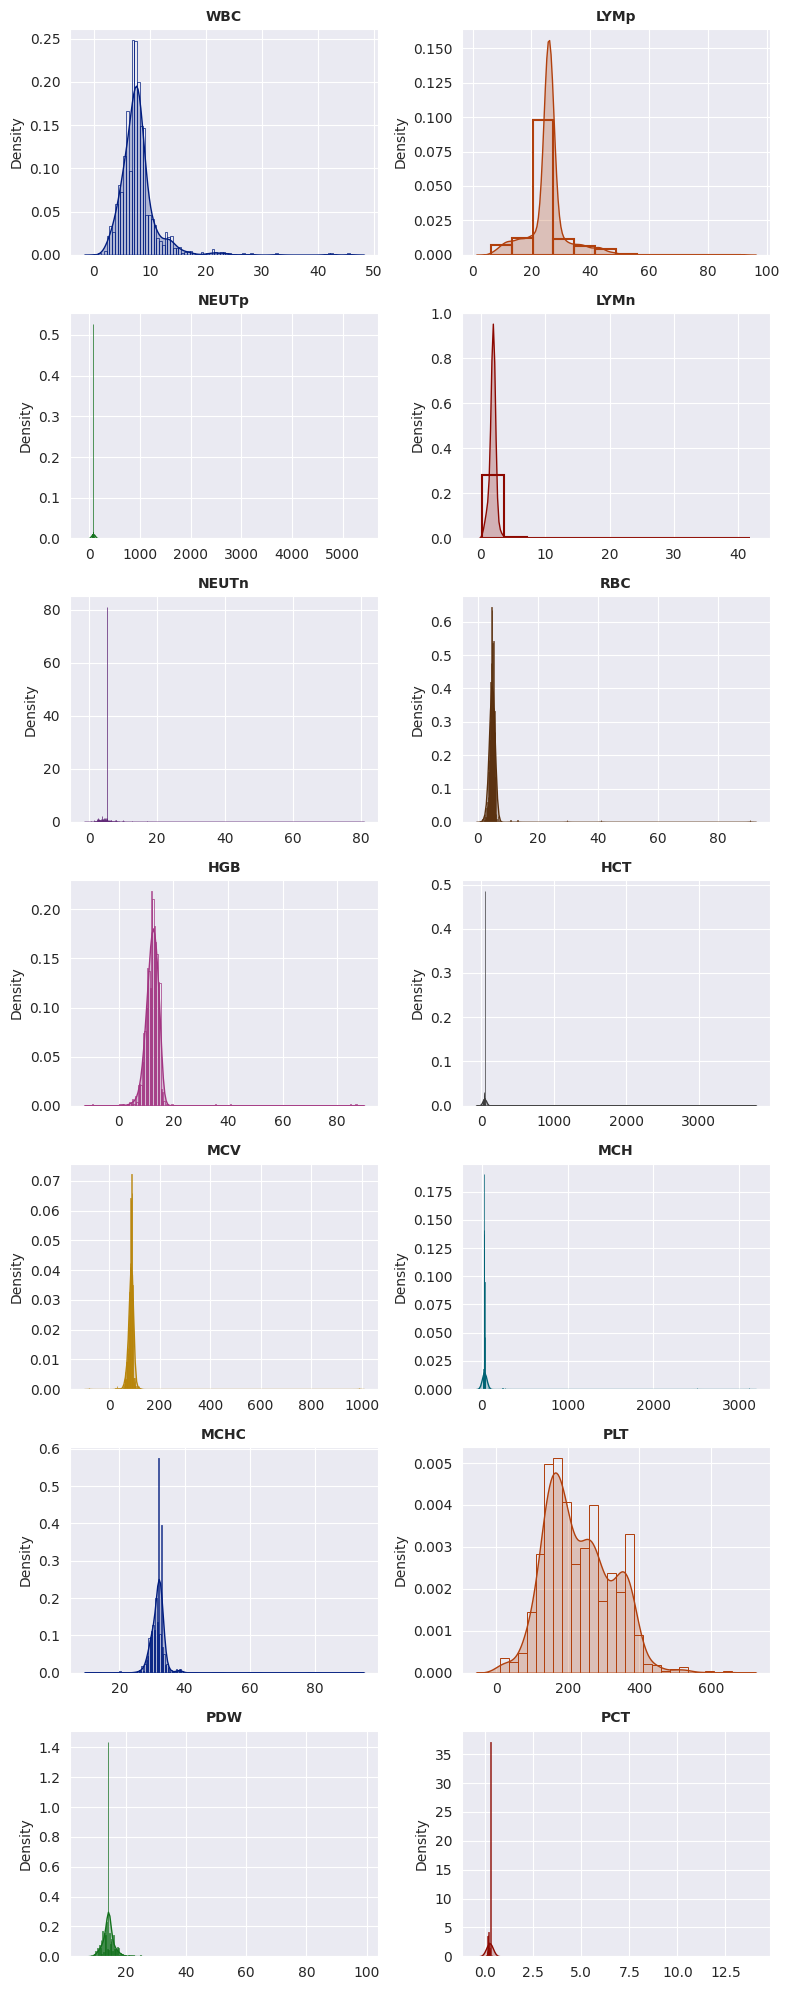

In [9]:
sns.set_style("darkgrid")
features = data.select_dtypes(include = ['int', 'float']).columns.to_list()
colors = sns.color_palette(palette = 'dark', n_colors = len(features))

fig,axs = plt.subplots(nrows = 7, ncols = 2, figsize = (8, 20))
axs = axs.flat

for i,feature in enumerate(features):
    sns.histplot(data, x = feature, stat = 'density', fill = False, color = colors[i], ax = axs[i])
    sns.kdeplot(data, x = feature, fill = True, color = colors[i], ax = axs[i])
    axs[i].set_xlabel("")
    axs[i].set_title(f"{feature}", fontsize = 10, fontweight = 'bold')

fig.tight_layout()
fig.show()

In [10]:
# As shown in the previous figure, the data needs to be scaled as the features scale is much different
# so we will scale our data
scaler = StandardScaler()
numerical_features = ['WBC', 'LYMp', 'NEUTp', 'LYMn', 'NEUTn', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'PLT', 'PDW', 'PCT']
data_scaled = data.copy()
data_scaled[numerical_features] = scaler.fit_transform(data_scaled[numerical_features])

In [11]:
data

,WBC,LYMp,NEUTp,LYMn,NEUTn,RBC,HGB,HCT,MCV,MCH,MCHC,PLT,PDW,PCT,Diagnosis
0,10.00,43.200,50.100,4.30000,5.00000,2.77,7.3,24.2000,87.7,26.3,30.1,189.0,12.500000,0.17000,Normocytic hypochromic anemia
1,10.00,42.400,52.300,4.20000,5.30000,2.84,7.3,25.0000,88.2,25.7,20.2,180.0,12.500000,0.16000,Normocytic hypochromic anemia
2,7.20,30.700,60.700,2.20000,4.40000,3.97,9.0,30.5000,77.0,22.6,29.5,148.0,14.300000,0.14000,Iron deficiency anemia
3,6.00,30.200,63.500,1.80000,3.80000,4.22,3.8,32.8000,77.9,23.2,29.8,143.0,11.300000,0.12000,Iron deficiency anemia
4,4.20,39.100,53.700,1.60000,2.30000,3.93,0.4,316.0000,80.6,23.9,29.7,236.0,12.800000,0.22000,Normocytic hypochromic anemia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1276,4.40,25.845,77.511,1.88076,5.14094,4.86,13.5,46.1526,80.7,27.7,34.4,180.0,14.312512,0.26028,Healthy
1277,5.60,25.845,77.511,1.88076,5.14094,4.85,15.0,46.1526,91.7,31.0,33.8,215.0,14.312512,0.26028,Healthy
1278,9.20,25.845,77.511,1.88076,5.14094,4.47,13.1,46.1526,88.7,29.3,33.0,329.0,14.312512,0.26028,Healthy
1279,6.48,25.845,77.511,1.88076,5.14094,4.75,13.2,46.1526,86.7,27.9,32.1,174.0,14.312512,0.26028,Healthy


In [12]:
data_scaled

,WBC,LYMp,NEUTp,LYMn,NEUTn,RBC,HGB,HCT,MCV,MCH,MCHC,PLT,PDW,PCT,Diagnosis
0,0.599843,2.466607e+00,-0.185600,1.811937,-0.049088,-0.688280,-1.281561,-0.209381,0.070161,-0.052056,-0.496853,-0.440741,-6.033850e-01,-0.131780,Normocytic hypochromic anemia
1,0.599843,2.352906e+00,-0.170704,1.737040,0.055399,-0.663423,-1.281561,-0.201751,0.088566,-0.057455,-3.497704,-0.537533,-6.033850e-01,-0.146376,Normocytic hypochromic anemia
2,-0.185996,6.900247e-01,-0.113827,0.239101,-0.258062,-0.262159,-0.835531,-0.149293,-0.323698,-0.085351,-0.678723,-0.881682,-4.165102e-03,-0.175570,Iron deficiency anemia
3,-0.522784,6.189614e-01,-0.094869,-0.060487,-0.467036,-0.173384,-2.199856,-0.127355,-0.290570,-0.079952,-0.587788,-0.935455,-1.002865e+00,-0.204763,Iron deficiency anemia
4,-1.027965,1.883888e+00,-0.161224,-0.210281,-0.989470,-0.276363,-3.091915,2.573771,-0.191184,-0.073653,-0.618099,0.064728,-5.035150e-01,-0.058796,Normocytic hypochromic anemia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1276,-0.971834,5.049352e-16,0.000000,0.000000,0.000000,0.053881,0.345135,0.000000,-0.187504,-0.039458,0.806547,-0.537533,-9.147597e-10,0.000000,Healthy
1277,-0.635046,5.049352e-16,0.000000,0.000000,0.000000,0.050330,0.738690,0.000000,0.217399,-0.009762,0.624678,-0.161120,-9.147597e-10,0.000000,Healthy
1278,0.375317,5.049352e-16,0.000000,0.000000,0.000000,-0.084609,0.240186,0.000000,0.106971,-0.025060,0.382184,1.064910,-9.147597e-10,0.000000,Healthy
1279,-0.388068,5.049352e-16,0.000000,0.000000,0.000000,0.014819,0.266424,0.000000,0.033352,-0.037658,0.109380,-0.602061,-9.147597e-10,0.000000,Healthy


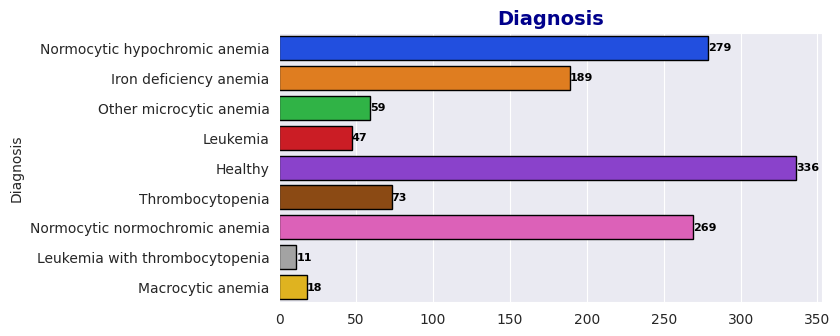

In [13]:
fig,ax = plt.subplots(figsize = (7,3.5))
ax = sns.countplot(data, y = 'Diagnosis', palette = 'bright', edgecolor = 'black')

for bars in ax.containers:
    ax.bar_label(bars, fontsize = 8, fontweight = 'bold', color = 'black')
    
ax.set_xlabel("")
ax.set_title('Diagnosis', fontsize = 14, fontweight = 'bold', color = 'darkblue')
fig.show()

In [14]:
fig = go.Figure(data=[go.Pie(labels=data['Diagnosis'], pull=[0.0,0.1],hole=0.5)])
fig.show()

In [15]:
# As shown our data is not balanced so we need to balance the data
# we need to encode the targer value and split the data first


# Separate features and target variable
X = data.drop(columns=['Diagnosis'])
y = data['Diagnosis']

# Encode target variable
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

In [16]:
# Split data into training, validation, and test sets
X_train, X_val_test, y_train, y_val_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_val_test, y_val_test, test_size=0.5, random_state=42)

In [17]:
# Apply SMOTE with reduced number of neighbors for balancing the data
smote = SMOTE(sampling_strategy='auto', k_neighbors=1, random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

In [18]:
# Data after apply SMOTE
fig = go.Figure(data=[go.Pie(labels=y_train_resampled,hole=0.5)])
fig.show()

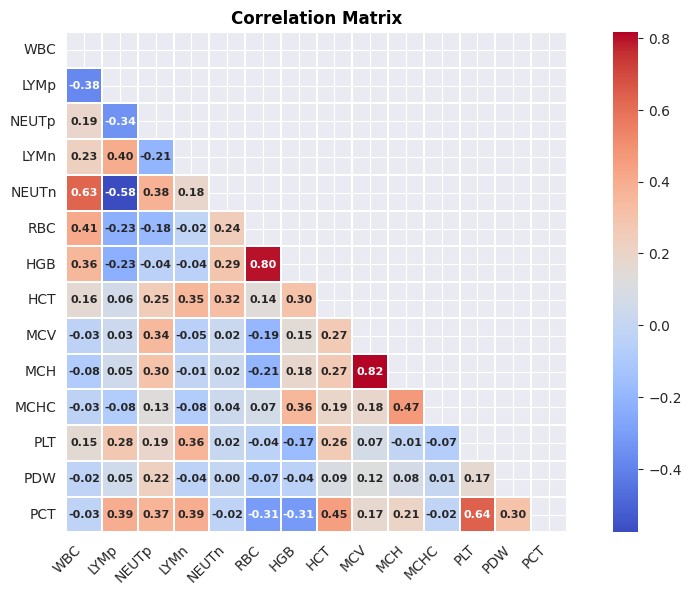

In [19]:
corr_matrix = X_train_resampled.corr(method = 'spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype = bool))

fig,ax = plt.subplots(figsize = (12,6.5))
sns.heatmap(corr_matrix, 
            cmap = 'coolwarm', 
            annot = True, 
            annot_kws = {'fontsize':8, 
                         'fontweight':'bold'},
            fmt = '.2f',
            linewidths = 1.2,
            square = True, 
            mask = mask, 
            ax = ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45, ha = 'right')
ax.set_title("Correlation Matrix", fontsize = 12, fontweight = 'bold', color = 'black')
fig.show()

#### Since there is no features greater than 0.9 we will use them all, no need for drop any

## The modeling part

In [24]:
# Comparing many alogrithms to see what acheives best accuracy
KN = KNeighborsClassifier()
LR = LogisticRegression()
DT = DecisionTreeClassifier()
#SV = SVC()
RF = RandomForestClassifier()
GB = GradientBoostingClassifier()
#LGBM = LGBMClassifier()
XG_B = XGBClassifier()
CB = CatBoostClassifier()
ET = ExtraTreeClassifier()
ETS = ExtraTreesClassifier()
algorithms = [KN,LR,DT,RF,GB,XG_B,CB,ET,ETS]

In [25]:
def compare_algorithms(X_train, y_train, algorithms, cv=10, scoring='accuracy'):
    """
    Compare the accuracies of multiple machine learning algorithms using cross-validation.

    Parameters:
    - X: Features (input variables) as a numpy array or pandas DataFrame.
    - y: Target variable as a numpy array or pandas Series.
    - algorithms: List of machine learning algorithms to compare.
    - cv: Number of cross-validation folds (default=10).
    - scoring: Evaluation metric to use (default='accuracy').

    Returns:
    - accuracies: Dictionary containing the accuracies of each algorithm.
    """

    accuracies = {}

    for algorithm in algorithms:
        algorithm.fit(X_train, y_train)
        scores = cross_val_score(algorithm, X_val_test, y_val_test, cv=cv, scoring=scoring)
        accuracies[type(algorithm).__name__] = np.mean(scores)

    return accuracies

In [26]:
def plot_accuracies(accuracies):
    """
    Plot a bar graph of accuracies for each algorithm.

    Parameters:
    - accuracies: Dictionary containing the accuracies of each algorithm.
    """

    algorithms = list(accuracies.keys())
    scores = list(accuracies.values())

    plt.figure(figsize=(10, 6))
    plt.barh(algorithms, scores, color='skyblue')
    plt.xlabel('Accuracy')
    plt.ylabel('Algorithm')
    plt.title('Accuracy of Machine Learning Algorithms')
    plt.xlim(0, 1)  # Set x-axis limits to range from 0 to 1
    plt.show()

In [ ]:
# Compare algorithms and plot accuracies
accuracies = compare_algorithms(X_train_resampled, y_train_resampled, algorithms)


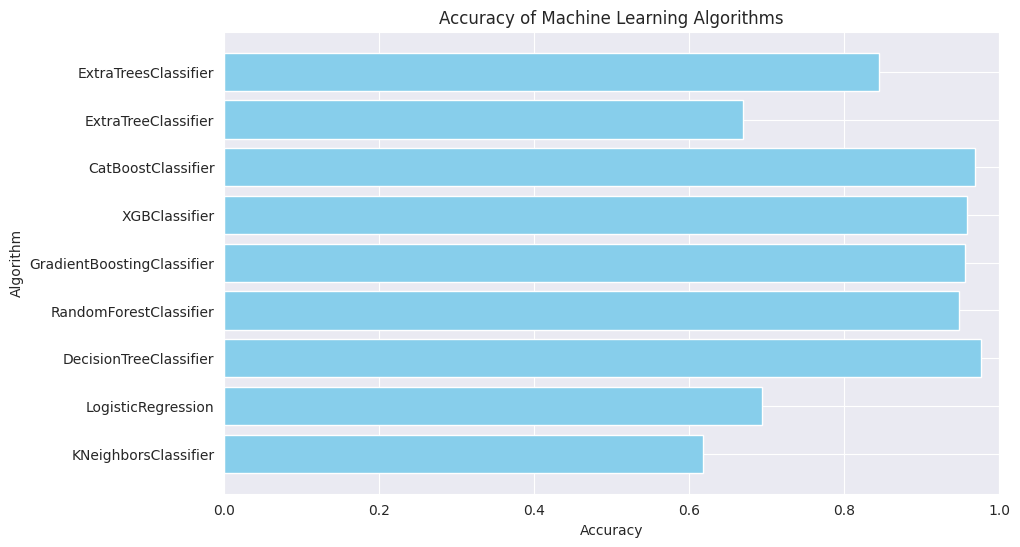

In [29]:
plot_accuracies(accuracies)

#### Decision Tree classifier has the best score, but it may be overfitting

#### We will train a Decision Tree classifier and try to prevent overfitting if exist

In [30]:
# fit and train the model
model = DecisionTreeClassifier()
model.fit(X_train_resampled,y_train_resampled)

DecisionTreeClassifier()

In [31]:
# Evaluate The model on training data
y_pred_train = model.predict(X_train)
train_accuracy = accuracy_score(y_train, y_pred_train)
print("Accuracy:", train_accuracy)
print('______________________________________________________')
print("Classification report: \n",classification_report(y_train, y_pred_train))
print('______________________________________________________')
print("\nConfusion Matrix:")
print(confusion_matrix(y_train, y_pred_train))

Accuracy: 1.0
______________________________________________________
Classification report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       216
           1       1.00      1.00      1.00       137
           2       1.00      1.00      1.00        37
           3       1.00      1.00      1.00         8
           4       1.00      1.00      1.00        16
           5       1.00      1.00      1.00       191
           6       1.00      1.00      1.00       200
           7       1.00      1.00      1.00        42
           8       1.00      1.00      1.00        49

    accuracy                           1.00       896
   macro avg       1.00      1.00      1.00       896
weighted avg       1.00      1.00      1.00       896

______________________________________________________

Confusion Matrix:
[[216   0   0   0   0   0   0   0   0]
 [  0 137   0   0   0   0   0   0   0]
 [  0   0  37   0   0   0   0   0   0]
 [  0   0 

In [32]:
# Evaluate The model on training data
y_pred_test = model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred_test)
print("Accuracy:", test_accuracy)
print('______________________________________________________')
print("Classification report: \n",classification_report(y_test, y_pred_test))
print('______________________________________________________')
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

Accuracy: 0.9896373056994818
______________________________________________________
Classification report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        59
           1       1.00      1.00      1.00        24
           2       1.00      1.00      1.00         5
           3       0.33      1.00      0.50         1
           5       1.00      1.00      1.00        41
           6       1.00      0.97      0.99        38
           7       1.00      0.89      0.94         9
           8       1.00      1.00      1.00        16

    accuracy                           0.99       193
   macro avg       0.92      0.98      0.93       193
weighted avg       1.00      0.99      0.99       193

______________________________________________________

Confusion Matrix:
[[59  0  0  0  0  0  0  0]
 [ 0 24  0  0  0  0  0  0]
 [ 0  0  5  0  0  0  0  0]
 [ 0  0  0  1  0  0  0  0]
 [ 0  0  0  0 41  0  0  0]
 [ 0  0  0  1  0 37  0  0]
 [ 0

In [33]:
# Evaluate The model on training data
y_pred_val = model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_pred_val)
print("Accuracy:", val_accuracy)
print('______________________________________________________')
print("Classification report: \n",classification_report(y_val, y_pred_val))
print('______________________________________________________')
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_val))

Accuracy: 0.9947916666666666
______________________________________________________
Classification report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        61
           1       1.00      0.96      0.98        28
           2       1.00      1.00      1.00         5
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00        47
           6       1.00      1.00      1.00        31
           7       0.89      1.00      0.94         8
           8       1.00      1.00      1.00         8

    accuracy                           0.99       192
   macro avg       0.99      1.00      0.99       192
weighted avg       1.00      0.99      0.99       192

______________________________________________________

Confusion Matrix:
[[61  0  0  0  0  0  0  0  0]
 [ 0 27  0  0  0  0  0  1  0]
 [ 0  0  5  0  0  0  0  0  0]
 [ 0  0  0  2  0  0  0

In [34]:
print(f"Acc Train: {balanced_accuracy_score(y_train, y_pred_train):.4f} | Acc Test: {balanced_accuracy_score(y_test, y_pred_test):.4f}")

Acc Train: 1.0000 | Acc Test: 0.9828


In [35]:
decision_tree = model

In [36]:

input_data = np.array([[10.1,25.845,77.511,1.88076,	5.14094,3.24,13.4,46.1526,124.1,41.4,33.3,237,14.31251157,0.26028]])  # Example input features
predictions = decision_tree.predict(input_data)
# Interpret predictions
for i, prediction in enumerate(predictions):
    print(f"Input data {i+1}:")
    print("Predicted class:", prediction)

Input data 1:
Predicted class: 2
